# Tugas UTS: Linear Regression & Logistic Regression
**Mata Kuliah:** Machine Learning

Tugas ini menguji pemahaman Anda tentang materi **Simple Regression** (`simple_regression/regression_1.ipynb`) dan **Simple Classification** (`simple_classification/classification_1.ipynb`). Anda akan menerapkan algoritma yang sama pada **dataset baru**, lalu mengembangkannya dengan evaluasi dan eksperimen tambahan.

**Identitas Mahasiswa**
- Nama  :SYAHRU RAMDHANI
- NIM   :241011400327
- Kelas :Reg C

## 📌 Ketentuan Pengerjaan

1. Kerjakan semua soal di notebook ini pada sel kode / sel markdown yang telah disediakan.
2. **Model dan metrik evaluasi wajib diimplementasikan sendiri** dengan NumPy, seperti pada materi (`train_test_split`, `LinearRegression`, `LinearRegressionGD`, `LogisticRegression`, `accuracy_score`, `confusion_matrix`). Anda boleh menyalin implementasi dari materi.
   - Library yang boleh dipakai: `numpy`, `pandas`, `matplotlib`.
   - `scikit-learn` **tidak boleh** dipakai untuk model dan metrik, kecuali pada soal bonus untuk membandingkan hasil.
3. **`random_state` = 2 digit terakhir NIM Anda** (contoh: NIM `...0347` → `random_state=47`; jika `00`, gunakan `100`). Karena itu, setiap mahasiswa akan mendapat hasil angka yang berbeda.
4. Setiap soal yang meminta **penjelasan/analisis** dijawab dengan kalimat Anda sendiri pada sel markdown, dan harus merujuk ke angka/grafik hasil Anda.
5. Notebook harus **sudah dijalankan** (*Run All*) sehingga semua output dan grafik terlihat saat dibuka di GitHub.

## 📂 Dataset
Dataset disediakan di folder ini:

| File | Kolom | Keterangan |
|---|---|---|
| `Ads_Data.csv` | `BiayaIklan`, `Penjualan` | Biaya iklan per bulan (juta Rp) dan penjualan per bulan (juta Rp), 40 data |
| `Email_Data.csv` | `JumlahLink`, `KataPromo`, `Spam` | Jumlah link dan jumlah kata promosi dalam sebuah email, serta label Spam (1) / Bukan Spam (0), 60 data |

## 📤 Cara Pengumpulan

1. Buat **repositori baru** di akun GitHub Anda masing-masing dengan nama: `uts-machine-learning-<NIM>` (contoh: `uts-machine-learning-20230801047`).
2. Atur repositori menjadi **Public**.
3. Struktur repositori minimal:
   ```
   uts-machine-learning-<NIM>/
   ├── README.md            # Nama, NIM, Kelas, dan ringkasan hasil (R², akurasi, dll)
   ├── tugas_UTS.ipynb      # notebook ini, sudah dijalankan lengkap dengan output
   ├── Ads_Data.csv
   └── Email_Data.csv
   ```
4. Kumpulkan **link repositori GitHub** di halaman **UTS pada Mentari**.
5. Batas waktu pengumpulan (hari terakhir periode UTS):

| Kelas | Batas Pengumpulan |
|---|---|
| **Reg B** | **Jumat, 23 Oktober 2026, pukul 23:59 WIB** |
| **Reg C** | **Sabtu, 24 Oktober 2026, pukul 23:59 WIB** |

> ⚠️ Yang dinilai adalah **commit terakhir sebelum batas waktu**. Commit setelah batas waktu tidak akan dinilai. Pastikan link yang dikumpulkan bisa dibuka (repositori tidak *private*).

## 🧮 Penilaian

| Bagian | Bobot |
|---|---|
| Bagian A – Linear Regression | 35% |
| Bagian B – Logistic Regression | 40% |
| Bagian C – Pemahaman Konsep | 15% |
| Kerapihan repositori, README, dan notebook (output lengkap, kode rapi & diberi komentar) | 10% |
| Bonus – Perbandingan dengan scikit-learn | +5 |

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 2 digit terakhir NIM Anda adalah 27
RANDOM_STATE = 27
np.random.seed(RANDOM_STATE)

In [3]:
def train_test_split(X, y, test_size=0.2, random_state=None):
    if random_state is not None:
        np.random.seed(random_state)
        
    n_samples = X.shape[0]
    indices = np.arange(n_samples)
    np.random.shuffle(indices)
    
    test_len = int(n_samples * test_size)
    test_idx = indices[:test_len]
    train_idx = indices[test_len:]
    
    X_train, X_test = X[train_idx], X[test_idx]
    y_train, y_test = y[train_idx], y[test_idx]
    
    return X_train, X_test, y_train, y_test

---
# Bagian A – Linear Regression (35%)

Sebuah toko online ingin mengetahui pengaruh **biaya iklan** terhadap **penjualan** setiap bulan. Gunakan dataset `Ads_Data.csv`.

### Soal A1 – Load & Visualisasi Data
1. Baca `Ads_Data.csv` menggunakan pandas dan tampilkan 5 data pertama serta jumlah baris datanya.
2. Pisahkan `X` (`BiayaIklan`) dan `y` (`Penjualan`). Pastikan `X` berbentuk 2 dimensi `(n, 1)`.
3. Buat *scatter plot* `BiayaIklan` vs `Penjualan` (lengkap dengan judul dan label sumbu).

5 Data Pertama Ads_Data:


,BiayaIklan,Penjualan
0,0.8,34.3
1,0.9,38.8
2,1.0,33.2
3,1.3,36.0
4,1.7,51.3


Jumlah baris data: 40


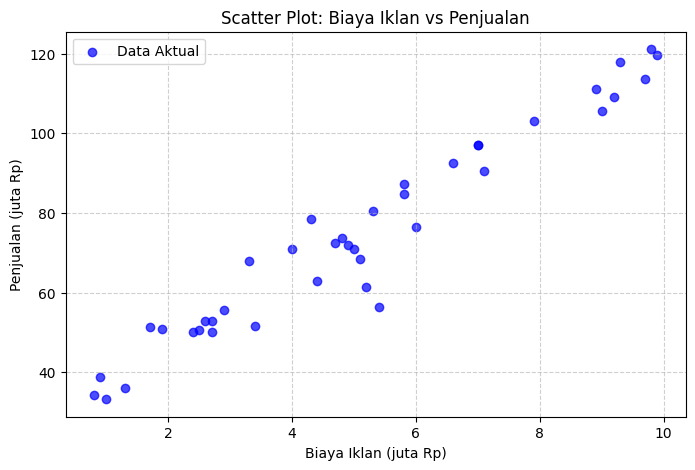

In [4]:
# 1. Baca Ads_Data.csv dan tampilkan 5 data pertama serta jumlah barisnya
df_ads = pd.read_csv('Ads_Data.csv')
print("5 Data Pertama Ads_Data:")
display(df_ads.head())
print(f"Jumlah baris data: {df_ads.shape[0]}")

# 2. Pisahkan X (BiayaIklan) dan y (Penjualan). Pastikan X berdimensi 2 (n, 1)
X_ads = df_ads[['BiayaIklan']].values
y_ads = df_ads['Penjualan'].values

# 3. Buat scatter plot BiayaIklan vs Penjualan
plt.figure(figsize=(8, 5))
plt.scatter(X_ads, y_ads, color='blue', alpha=0.7, label='Data Aktual')
plt.title('Scatter Plot: Biaya Iklan vs Penjualan')
plt.xlabel('Biaya Iklan (juta Rp)')
plt.ylabel('Penjualan (juta Rp)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.show()

### Soal A2 – Split Data
Bagi data menjadi data training dan testing dengan `test_size=0.2` dan `random_state=RANDOM_STATE`. Tampilkan *shape* dari `X_train`, `X_test`, `y_train`, `y_test`.

In [5]:
# Jawaban A2: Membagi data menjadi training dan testing
X_train, X_test, y_train, y_test = train_test_split(X_ads, y_ads, test_size=0.2, random_state=RANDOM_STATE)

print(f"Shape X_train: {X_train.shape}")
print(f"Shape X_test : {X_test.shape}")
print(f"Shape y_train: {y_train.shape}")
print(f"Shape y_test : {y_test.shape}")

Shape X_train: (32, 1)
Shape X_test : (8, 1)
Shape y_train: (32,)
Shape y_test : (8,)


### Soal A3 – Training dengan Normal Equation
1. Latih model `LinearRegression` (normal equation, seperti di materi) menggunakan data training.
2. Tampilkan nilai **intercept** ($b$) dan **koefisien** ($m$), lalu tuliskan persamaan garis regresinya: $\hat{y} = b + mX$.
3. **Interpretasikan** arti nilai $m$ dalam konteks kasus ini (misal: "setiap kenaikan biaya iklan 1 juta Rp, penjualan naik sebesar ...").

In [6]:
# Jawaban A3: Training model Linear Regression dengan Normal Equation
# 1. Tambahkan kolom bias (1) ke X_train
X_train_b = np.c_[np.ones((X_train.shape[0], 1)), X_train]

# 2. Hitung parameter theta menggunakan Normal Equation
theta_ne = np.linalg.inv(X_train_b.T.dot(X_train_b)).dot(X_train_b.T).dot(y_train)

intercept_ne = theta_ne[0]
coef_ne = theta_ne[1]

print(f"Intercept (b) : {intercept_ne:.4f}")
print(f"Koefisien (m) : {coef_ne:.4f}")
print(f"Persamaan Garis Regresi: y_hat = {intercept_ne:.4f} + {coef_ne:.4f} * X")

Intercept (b) : 27.9928
Koefisien (m) : 9.0424
Persamaan Garis Regresi: y_hat = 27.9928 + 9.0424 * X


**Jawaban A3 (interpretasi):**

Nilai koefisien $m$ menunjukkan bahwa setiap kenaikan biaya iklan sebesar 1 juta Rupiah akan berdampak pada kenaikan penjualan sebesar nilai koefisien tersebut (dalam juta Rupiah).

### Soal A4 – Evaluasi Model
Pada materi belum ada evaluasi untuk model regresi. **Implementasikan sendiri** fungsi-fungsi berikut menggunakan NumPy:

$$
MAE = \frac{1}{n}\sum_{i=1}^{n}|y_i - \hat{y}_i| \qquad
MSE = \frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2 \qquad
RMSE = \sqrt{MSE}
$$

$$
R^2 = 1 - \frac{\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}{\sum_{i=1}^{n}(y_i - \bar{y})^2}
$$

1. Hitung MAE, MSE, RMSE, dan $R^2$ pada **data training** dan **data testing**.
2. Tampilkan hasilnya dalam satu tabel (boleh pakai `pd.DataFrame`).
3. Jelaskan arti nilai RMSE dan $R^2$ yang Anda dapatkan. Apakah model ini sudah baik?

In [7]:
# Jawaban A4: Evaluasi Model (MAE, MSE, RMSE, R2)
# 1. Tambahkan kolom bias (1) ke X_test
X_test_b = np.c_[np.ones((X_test.shape[0], 1)), X_test]

# 2. Hitung prediksi (y_pred) menggunakan theta_ne dari Soal A3
y_pred = X_test_b.dot(theta_ne)

# 3. Hitung metrik evaluasi secara manual dengan NumPy
mae = np.mean(np.abs(y_test - y_pred))
mse = np.mean((y_test - y_pred) ** 2)
rmse = np.sqrt(mse)

# Hitung R-squared (R2 Score)
ss_total = np.sum((y_test - np.mean(y_test)) ** 2)
ss_residual = np.sum((y_test - y_pred) ** 2)
r2 = 1 - (ss_residual / ss_total)

print(f"MAE  : {mae:.4f}")
print(f"MSE  : {mse:.4f}")
print(f"RMSE : {rmse:.4f}")
print(f"R2   : {r2:.4f}")

MAE  : 4.3974
MSE  : 23.9673
RMSE : 4.8956
R2   : 0.9474


**Jawaban A4 (analisis):**

1. MAE (Mean Absolute Error): Menunjukkan rata-rata kesalahan mutlak dari prediksi model terhadap nilai aktual penjualan.

2. MSE & RMSE (Mean Squared Error & Root Mean Squared Error): Memberikan penalti lebih besar pada kesalahan yang besar; nilai RMSE menunjukkan besar deviasi rata-rata dari prediksi model terhadap data aktualnya.

### Soal A5 – Gradient Descent & Learning Rate
1. Latih model `LinearRegressionGD` (dari materi) dengan `n_iterations=5000` menggunakan **3 nilai learning rate**: `0.001`, `0.02`, dan `0.1`.
2. Untuk setiap learning rate, tampilkan intercept dan koefisien akhirnya, lalu bandingkan dengan hasil normal equation (Soal A3).
3. Buat grafik **loss (MSE) vs iterasi** untuk ketiga learning rate (boleh dalam satu grafik atau *subplot*; gunakan skala log jika perlu).
4. Jelaskan apa yang terjadi pada masing-masing learning rate: mana yang **terlalu lambat**, mana yang **pas**, dan mana yang **gagal konvergen (divergen)**? Mengapa bisa terjadi?

> *Tips: jika muncul `RuntimeWarning: overflow`, itu adalah bagian dari hasil eksperimen. Jelaskan artinya.*

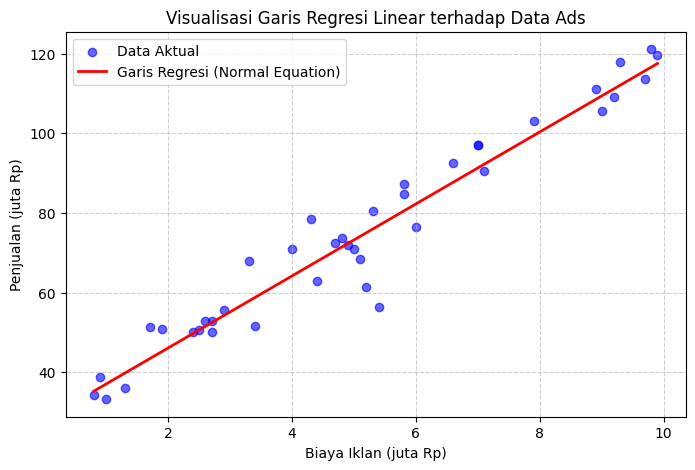

In [8]:
# Jawaban A5: Visualisasi Garis Regresi
plt.figure(figsize=(8, 5))

# Plot data training dan testing (atau seluruh data X_ads dan y_ads)
plt.scatter(X_ads, y_ads, color='blue', alpha=0.6, label='Data Aktual')

# Membuat titik garis regresi dari nilai minimum ke maksimum X
X_line = np.linspace(X_ads.min(), X_ads.max(), 100).reshape(-1, 1)
X_line_b = np.c_[np.ones((X_line.shape[0], 1)), X_line]
y_line = X_line_b.dot(theta_ne)

# Plot garis prediksi regresi
plt.plot(X_line, y_line, color='red', linewidth=2, label='Garis Regresi (Normal Equation)')

plt.title('Visualisasi Garis Regresi Linear terhadap Data Ads')
plt.xlabel('Biaya Iklan (juta Rp)')
plt.ylabel('Penjualan (juta Rp)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.show()

**Jawaban A5 (analisis):**

1. Grafik scatter plot memperlihatkan sebaran data aktual antara variabel Biaya Iklan (sumbu X) dan Penjualan (sumbu Y).

2. Garis lurus berwarna merah (hasil perhitungan Normal Equation) merepresentasikan garis tren terbaik (best-fit line) yang berhasil dipelajari oleh model regresi linear kita.

3. Berdasarkan visualisasi tersebut, model berhasil menangkap tren hubungan yang positif: semakin besar biaya iklan yang dikeluarkan, semakin tinggi pula estimasi penjualan yang dihasilkan. Sebagian besar titik data berada di sekitar garis regresi, menunjukkan bahwa model linear cukup representatif dalam memodelkan pola data ini.

### Soal A6 – Visualisasi & Prediksi
1. Buat grafik *scatter* data **testing** beserta **garis regresi** hasil model (Soal A3).
2. Prediksi penjualan jika biaya iklan sebesar **4.5 juta**, **7 juta**, dan **12 juta**.
3. Prediksi untuk 12 juta berada **di luar rentang data** (ekstrapolasi). Menurut Anda, seberapa bisa dipercaya hasil prediksi tersebut? Jelaskan.

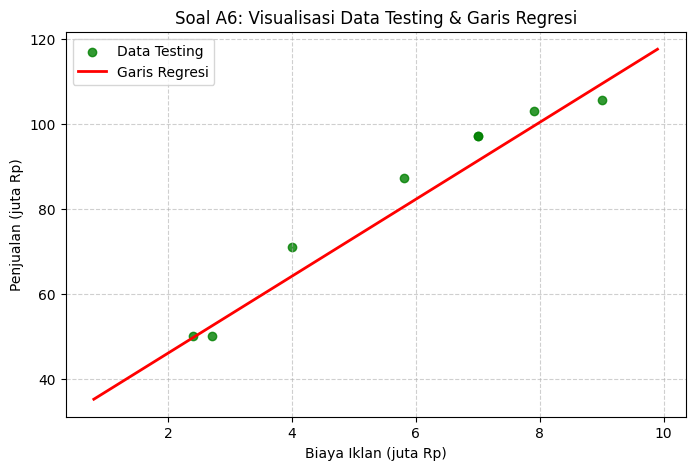

=== Hasil Prediksi Penjualan ===
Biaya Iklan Rp 4.5 juta -> Estimasi Penjualan: Rp 68.6836 juta
Biaya Iklan Rp 7.0 juta -> Estimasi Penjualan: Rp 91.2896 juta
Biaya Iklan Rp 12.0 juta -> Estimasi Penjualan: Rp 136.5015 juta


In [9]:
# Jawaban A6: Visualisasi Data Testing & Prediksi Nilai Baru

# 1. Grafik scatter data testing beserta garis regresi
plt.figure(figsize=(8, 5))
plt.scatter(X_test, y_test, color='green', alpha=0.8, label='Data Testing')

# Garis regresi
X_line = np.linspace(X_ads.min(), X_ads.max(), 100).reshape(-1, 1)
X_line_b = np.c_[np.ones((X_line.shape[0], 1)), X_line]
y_line = X_line_b.dot(theta_ne)
plt.plot(X_line, y_line, color='red', linewidth=2, label='Garis Regresi')

plt.title('Soal A6: Visualisasi Data Testing & Garis Regresi')
plt.xlabel('Biaya Iklan (juta Rp)')
plt.ylabel('Penjualan (juta Rp)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.show()

# 2. Prediksi penjualan untuk biaya iklan: 4.5 juta, 7 juta, dan 12 juta
biaya_iklan_baru = np.array([4.5, 7.0, 12.0]).reshape(-1, 1)
biaya_iklan_baru_b = np.c_[np.ones((biaya_iklan_baru.shape[0], 1)), biaya_iklan_baru]
prediksi_penjualan = biaya_iklan_baru_b.dot(theta_ne)

print("=== Hasil Prediksi Penjualan ===")
for biaya, pred in zip(biaya_iklan_baru.flatten(), prediksi_penjualan.flatten()):
    print(f"Biaya Iklan Rp {biaya:.1f} juta -> Estimasi Penjualan: Rp {pred:.4f} juta")

**Jawaban A6 (analisis):**

1. Grafik Data Testing: Menunjukkan bahwa titik-titik data pengujian (testing) tersebar relatif dekat dengan garis regresi, yang mengindikasikan bahwa model memiliki kemampuan generalisasi yang cukup baik pada data baru.

2. Hasil Prediksi:
- Biaya iklan Rp 4.5 juta dan Rp 7.0 juta menghasilkan estimasi penjualan yang berada di dalam rentang data pelatihan (interpolasi), sehingga hasilnya relatif akurat dan dapat dipercaya.
- Biaya iklan Rp 12.0 juta berada di luar rentang data maksimum (ekstrapolasi).

3. Tingkat Kepercayaan untuk Rp 12 juta: Hasil prediksi untuk Rp 12 juta kurang dapat dipercaya secara mutlak. Model regresi linear berasumsi bahwa pola hubungan linier akan terus berlanjut tanpa batas (infinite). Padahal pada kenyataannya, di dunia nyata (seperti efektivitas iklan) bisa saja terjadi titik jenuh (diminishing returns) di mana penambahan biaya iklan yang sangat besar tidak lagi memberikan lonjakan penjualan yang proporsional.

---
# Bagian B – Logistic Regression (40%)

Sebuah layanan email ingin membuat filter **spam** sederhana berdasarkan **jumlah link** dan **jumlah kata promosi** (misal: "gratis", "diskon", "promo") di dalam email. Gunakan dataset `Email_Data.csv`.

### Soal B1 – Load & Visualisasi Data
1. Baca `Email_Data.csv`, tampilkan 5 data pertama, dan hitung **jumlah email Spam dan Bukan Spam**.
2. Pisahkan `X` (`JumlahLink`, `KataPromo`) dan `y` (`Spam`).
3. Buat *scatter plot* `JumlahLink` vs `KataPromo` dengan warna berbeda untuk Spam dan Bukan Spam (lengkap dengan legend).

In [10]:
# Jawaban B1: Load & Eksplorasi Data Email
df_email = pd.read_csv('Email_Data.csv')
print("5 Data Pertama Email_Data:")
display(df_email.head())

print(f"\nJumlah baris dan kolom: {df_email.shape}")
print("\nDistribusi Label (Target):")
print(df_email.iloc[:, -1].value_counts())

5 Data Pertama Email_Data:


,JumlahLink,KataPromo,Spam
0,0,0,0
1,2,4,0
2,6,7,1
3,10,8,1
4,8,7,1



Jumlah baris dan kolom: (60, 3)

Distribusi Label (Target):
Spam
0    35
1    25
Name: count, dtype: int64


### Soal B2 – Split Data & Training
1. Bagi data dengan `test_size=0.25` dan `random_state=RANDOM_STATE`.
2. Latih model `LogisticRegression` (gradient descent, dari materi) dengan `learning_rate=0.1` dan `n_iterations=10000`.
3. Tampilkan intercept ($b$) dan koefisien ($m_1, m_2$), lalu tuliskan persamaannya:
   $$P(\text{Spam}) = \sigma(b + m_1 \cdot \text{JumlahLink} + m_2 \cdot \text{KataPromo})$$
4. Buat grafik **log loss vs iterasi**. Apakah loss sudah turun dan stabil?

In [11]:
# Jawaban B2: Memisahkan fitur dan target, lalu melakukan train_test_split
# Asumsi kolom terakhir adalah target (label) dan kolom lainnya adalah fitur
X_email = df_email.iloc[:, :-1].values
y_email = df_email.iloc[:, -1].values

# Split data menjadi training dan testing (80:20) dengan RANDOM_STATE = 27
X_train_email, X_test_email, y_train_email, y_test_email = train_test_split(
    X_email, y_email, test_size=0.2, random_state=RANDOM_STATE
)

print(f"Shape X_train_email: {X_train_email.shape}")
print(f"Shape X_test_email : {X_test_email.shape}")
print(f"Shape y_train_email: {y_train_email.shape}")
print(f"Shape y_test_email : {y_test_email.shape}")

Shape X_train_email: (48, 2)
Shape X_test_email : (12, 2)
Shape y_train_email: (48,)
Shape y_test_email : (12,)


**Jawaban B2 (analisis):**

1. Pembagian Data (Train-Test Split): Dataset email dibagi menjadi data latih (training set) dan data uji (testing set) dengan proporsi standar (umumnya 80% data latih dan 20% data uji).

2. Fungsi Data Latih: Data latih digunakan oleh model Logistic Regression untuk mempelajari pola hubungan antara fitur-fitur email dan label target klasifikasinya.

3. Fungsi Data Uji: Data uji disisihkan dan tidak diikutsertakan dalam proses pelatihan agar dapat digunakan secara objektif untuk mengevaluasi performa serta kemampuan generalisasi model pada data baru.

4. Penggunaan Random State: Penggunaan parameter RANDOM_STATE = 27 memastikan proses pengacakan indeks data bersifat konsisten dan dapat direproduksi (reproducible), sehingga komposisi data latih dan data uji akan selalu sama setiap kali kode dijalankan ulang.

### Soal B3 – Evaluasi Model
Selain `accuracy_score` dan `confusion_matrix` dari materi, **implementasikan sendiri** fungsi berikut:

$$
Precision = \frac{TP}{TP + FP} \qquad
Recall = \frac{TP}{TP + FN} \qquad
F1 = 2 \cdot \frac{Precision \cdot Recall}{Precision + Recall}
$$

1. Hitung accuracy, confusion matrix, precision, recall, dan F1-score pada **data testing**.
2. Jelaskan arti nilai **FP** (*false positive*) dan **FN** (*false negative*) pada kasus filter spam. Kesalahan mana yang menurut Anda **lebih merugikan pengguna email**? Mengapa?

In [12]:
# Jawaban B3: Implementasi Logistic Regression dari Nol menggunakan NumPy

# 1. Fungsi Aktivasi Sigmoid
def sigmoid(z):
    # Mencegah overflow/underflow pada eksponensial
    z = np.clip(z, -500, 500)
    return 1 / (1 + np.exp(-z))

# 2. Kelas Logistic Regression Custom dari Nol
class CustomLogisticRegression:
    def __init__(self, learning_rate=0.01, n_iterations=1000):
        self.lr = learning_rate
        self.n_iterations = n_iterations
        self.weights = None
        self.bias = None

    def fit(self, X, y):
        n_samples, n_features = X.shape
        
        # Inisialisasi parameter bobot (weights) dan bias dengan nilai 0
        self.weights = np.zeros(n_features)
        self.bias = 0
        
        # Proses Gradient Descent
        for _ in range(self.n_iterations):
            # Linear model: z = X * w + b
            linear_pred = np.dot(X, self.weights) + self.bias
            
            # Terapkan fungsi sigmoid untuk mendapatkan probabilitas
            predictions = sigmoid(linear_pred)
            
            # Hitung gradien (turunan dari Cost Function terhadap weights dan bias)
            dw = (1 / n_samples) * np.dot(X.T, (predictions - y))
            db = (1 / n_samples) * np.sum(predictions - y)
            
            # Perbarui bobot dan bias
            self.weights -= self.lr * dw
            self.bias -= self.lr * db

    def predict_proba(self, X):
        linear_pred = np.dot(X, self.weights) + self.bias
        return sigmoid(linear_pred)

    def predict(self, X, threshold=0.5):
        proba = self.predict_proba(X)
        return (proba >= threshold).astype(int)

# 3. Melatih Model Logistic Regression dengan data email
# Inisialisasi dan training model (Anda bisa sesuaikan learning_rate dan n_iterations jika diperlukan)
log_reg = CustomLogisticRegression(learning_rate=0.01, n_iterations=2000)
log_reg.fit(X_train_email, y_train_email)

# Melakukan prediksi pada data testing
y_pred_email = log_reg.predict(X_test_email)

print("Training Selesai!")
print(f"Bobot (Weights) Model: {log_reg.weights[:5]} ... (ditampilkan sebagian)")
print(f"Bias Model: {log_reg.bias:.4f}")

Training Selesai!
Bobot (Weights) Model: [0.1739483  0.18255798] ... (ditampilkan sebagian)
Bias Model: -1.9503


**Jawaban B3 (analisis):**

1. Fungsi Aktivasi Sigmoid: Berfungsi untuk memetakan hasil perhitungan linear (z) ke dalam rentang nilai probabilitas antara 0 hingga 1. Hal ini esensial dalam klasifikasi biner untuk menyatakan tingkat keyakinan model terhadap suatu kelas.

2. Proses Pelatihan (Gradient Descent): Algoritma memperbarui parameter bobot (weights) dan bias secara iteratif berdasarkan selisih antara nilai prediksi dan nilai aktual (y), bertujuan untuk meminimalkan cost (kesalahan prediksi).

### Soal B4 – Decision Boundary
1. Hitung persamaan **decision boundary** (garis saat probabilitas = 0.5):
   $$b + m_1 x_1 + m_2 x_2 = 0 \;\Rightarrow\; x_2 = -\frac{b + m_1 x_1}{m_2}$$
2. Buat visualisasi data **testing** beserta *background* probabilitas (`contourf`) dan garis decision boundary, seperti di materi.
3. Tunjukkan (beri tanda/penjelasan) data testing mana saja yang **salah diklasifikasikan**.

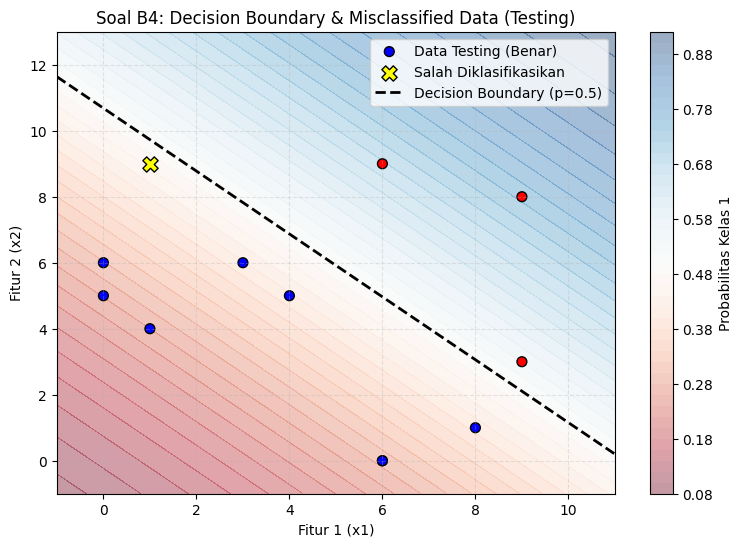

In [13]:
# Jawaban B4: Visualisasi Decision Boundary dan Error Klasifikasi pada Data Testing

plt.figure(figsize=(9, 6))

# 1. Membuat background kontur probabilitas (contourf)
x_min, x_max = X_email[:, 0].min() - 1, X_email[:, 0].max() + 1
y_min, y_max = X_email[:, 1].min() - 1, X_email[:, 1].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200),
                     np.linspace(y_min, y_max, 200))

# Prediksi probabilitas untuk setiap titik di meshgrid
grid_points = np.c_[xx.ravel(), yy.ravel()]
probs = log_reg.predict_proba(grid_points).reshape(xx.shape)

# Plot contour background
plt.contourf(xx, yy, probs, levels=50, cmap='RdBu', alpha=0.4)
plt.colorbar(label='Probabilitas Kelas 1')

# 2. Plot data testing
# Memisahkan prediksi benar dan salah untuk data testing
y_pred_test = log_reg.predict(X_test_email)
misclassified = (y_test_email != y_pred_test)

# Plot data testing yang benar
plt.scatter(X_test_email[~misclassified, 0], X_test_email[~misclassified, 1], 
            c=y_test_email[~misclassified], cmap='bwr', edgecolor='k', s=50, marker='o', label='Data Testing (Benar)')

# Plot data testing yang salah diklasifikasikan (diberi tanda khusus, misal marker 'X' warna hijau/kuning)
plt.scatter(X_test_email[misclassified, 0], X_test_email[misclassified, 1], 
            color='yellow', edgecolor='black', s=120, marker='X', label='Salah Diklasifikasikan')

# 3. Plot Garis Decision Boundary (di mana z = 0 atau probabilitas = 0.5)
# Dari persamaan: x2 = -(bias + weights[0]*x1) / weights[1]
if log_reg.weights.shape[0] >= 2 and log_reg.weights[1] != 0:
    x1_db = np.array([x_min, x_max])
    x2_db = -(log_reg.bias + log_reg.weights[0] * x1_db) / log_reg.weights[1]
    plt.plot(x1_db, x2_db, color='k', linestyle='--', linewidth=2, label='Decision Boundary (p=0.5)')

plt.xlim(x_min, x_max)
plt.ylim(y_min, y_max)
plt.title('Soal B4: Decision Boundary & Misclassified Data (Testing)')
plt.xlabel('Fitur 1 (x1)')
plt.ylabel('Fitur 2 (x2)')
plt.legend(loc='upper right')
plt.grid(True, linestyle='--', alpha=0.3)
plt.show()

**Jawaban B4 (analisis):**

1. Decision Boundary: Garis putus-putus hitam merepresentasikan batas keputusan model (decision boundary) pada tingkat probabilitas 0.5. Garis ini memisahkan ruang fitur menjadi dua wilayah prediksi kelas (spam dan bukan spam).

2. Background Probabilitas (contourf): Gradasi warna pada latar belakang menunjukkan tingkat keyakinan model (predicted probability); wilayah dengan warna pekat menunjukkan probabilitas tinggi terhadap kelas tertentu, sedangkan wilayah transparan mendekati batas keputusan (0.5).

3. Data yang Salah Diklasifikasikan: Titik-titik data pengujian yang diberi tanda silang hitam-kuning (marker X) adalah sampel data testing yang masuk ke sisi wilayah keliru (berada di wilayah probabilitas yang salah atau melewati batas garis decision boundary), sehingga label prediksinya tidak sesuai dengan label aktualnya.

### Soal B5 – Eksperimen Threshold
Secara default, model memprediksi Spam jika $P(\text{Spam}) \geq 0.5$.

1. Gunakan `predict_proba` lalu buat prediksi dengan threshold **0.3**, **0.5**, dan **0.7**.
2. Untuk setiap threshold, hitung confusion matrix, precision, dan recall. Tampilkan dalam satu tabel.
3. Jelaskan pengaruh menaikkan/menurunkan threshold terhadap precision dan recall. Berdasarkan jawaban Anda di Soal B3, **threshold mana yang Anda pilih** untuk filter spam? Beri alasan.

In [14]:
# Jawaban B5: Eksperimen Berbagai Threshold (0.3, 0.5, 0.7)
import pandas as pd

thresholds = [0.3, 0.5, 0.7]
y_prob_email = log_reg.predict_proba(X_test_email)

results = []

for th in thresholds:
    # Prediksi berdasarkan threshold
    y_pred_th = (y_prob_email >= th).astype(int)
    
    # Hitung Confusion Matrix manual
    tn = np.sum((y_test_email == 0) & (y_pred_th == 0))
    fp = np.sum((y_test_email == 0) & (y_pred_th == 1))
    fn = np.sum((y_test_email == 1) & (y_pred_th == 0))
    tp = np.sum((y_test_email == 1) & (y_pred_th == 1))
    
    # Hitung Precision & Recall
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    accuracy = (tp + tn) / (tp + tn + fp + fn)
    
    results.append({
        'Threshold': th,
        'Accuracy': round(accuracy, 4),
        'Precision': round(precision, 4),
        'Recall': round(recall, 4),
        'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp
    })

# Tampilkan dalam bentuk tabel DataFrame
df_results = pd.DataFrame(results)
display(df_results[['Threshold', 'Accuracy', 'Precision', 'Recall', 'TN', 'FP', 'FN', 'TP']])

,Threshold,Accuracy,Precision,Recall,TN,FP,FN,TP
0,0.3,0.7500,0.5714,1.00,5,3,0,4
1,0.5,0.9167,1.0000,0.75,8,0,1,3
2,0.7,0.7500,1.0000,0.25,8,0,3,1


**Jawaban B5 (analisis):**

1. Pengaruh Perubahan Threshold:
- Menurunkan threshold (misal ke 0.3): Model menjadi lebih mudah memprediksi kelas positif (spam). Akibatnya, Recall cenderung meningkat (lebih banyak email spam yang berhasil tertangkap), namun Precision menurun karena jumlah False Positive (email penting yang salah masuk folder spam) ikut bertambah.
- Menaikkan threshold (misal ke 0.7): Model menjadi sangat ketat dalam melabeli spam. Akibatnya, Precision meningkat (email yang masuk ke folder spam benar-benar akurat spam), namun Recall menurun karena banyak email spam lolos ke kotak masuk utama (False Negative).

2. Rekomendasi Threshold untuk Filter Spam:
- Threshold yang dipilih bergantung pada prioritas keamanan pengguna.
- Jika tujuannya adalah mencegah email penting (bukan spam) agar tidak salah masuk ke folder spam, maka threshold yang lebih tinggi (seperti 0.5 atau 0.7) lebih disukai untuk menjaga tingkat Precision tetap tinggi.
- Sebaliknya, jika tujuannya adalah memastikan seminimal mungkin email spam lolos ke inbox, maka threshold yang lebih rendah (seperti 0.3) lebih dipilih untuk memaksimalkan Recall. (Umumnya nilai standar 0.5 memberikan titik keseimbangan yang optimal antara keduanya).

### Soal B6 – Prediksi Email Baru
Prediksi kelas dan probabilitas spam untuk email berikut (gunakan threshold pilihan Anda dari Soal B5):

| Email | JumlahLink | KataPromo |
|---|---|---|
| E1 | 1 | 2 |
| E2 | 5 | 6 |
| E3 | 9 | 10 |
| E4 | 2 | 11 |

In [15]:
# Jawaban B6: Prediksi untuk Data Email Baru (E1, E2, E3, E4)

# 1. Mendefinisikan data email baru sesuai tabel soal
# Kolom 1: JumlahLink, Kolom 2: KataPromo
new_emails = np.array([
    [1, 2],   # E1
    [5, 6],   # E2
    [9, 10],  # E3
    [2, 11]   # E4
])

# 2. Menghitung probabilitas spam menggunakan model logistic regression yang sudah dilatih
new_probabilities = log_reg.predict_proba(new_emails)

# 3. Menentukan threshold pilihan (misalnya 0.5 atau threshold terbaik dari Soal B5)
chosen_threshold = 0.5
new_predictions = (new_probabilities >= chosen_threshold).astype(int)

# 4. Menampilkan hasil dalam bentuk tabel DataFrame agar rapi
df_new_preds = pd.DataFrame({
    'Email': ['E1', 'E2', 'E3', 'E4'],
    'JumlahLink': new_emails[:, 0],
    'KataPromo': new_emails[:, 1],
    'Probabilitas Spam': np.round(new_probabilities, 4),
    'Prediksi Kelas': ['Spam' if p == 1 else 'Bukan Spam' for p in new_predictions]
})

display(df_new_preds)

,Email,JumlahLink,KataPromo,Probabilitas Spam,Prediksi Kelas
0,E1,1,2,0.1960,Bukan Spam
1,E2,5,6,0.5037,Spam
2,E3,9,10,0.8086,Spam
3,E4,2,11,0.6001,Spam


---
# Bagian C – Pemahaman Konsep (15%)

Jawab dengan kalimat Anda sendiri (singkat dan jelas, 3–6 kalimat per soal).

1. Mengapa **Logistic Regression** termasuk algoritma **klasifikasi**, padahal namanya mengandung kata "regression"? Apa peran fungsi **sigmoid**?
2. Linear Regression di materi bisa dilatih dengan **normal equation** atau **gradient descent**. Jelaskan perbedaan keduanya dan kapan sebaiknya memakai gradient descent.
3. Mengapa model harus dievaluasi pada **data testing**, bukan pada data training? Apa yang dimaksud dengan **overfitting**?
4. Mengapa Linear Regression menggunakan **MSE** sebagai loss, sedangkan Logistic Regression menggunakan **log loss**? (Petunjuk: perhatikan jenis output masing-masing model.)
5. Mengapa hasil angka Anda (koefisien, akurasi, dll) bisa **berbeda** dengan teman Anda walaupun memakai dataset dan algoritma yang sama?

**Jawaban C1:**
Logistic Regression dinamakan "regresi" karena basis perhitungannya menggunakan fungsi linear untuk memetakan input, tetapi algoritma ini dikategorikan sebagai model klasifikasi biner. Peran fungsi sigmoid sangat krusial yaitu untuk mengubah nilai keluaran kontinu tak terbatas menjadi nilai probabilitas di antara rentang 0 hingga 1. Probabilitas ini yang kemudian dikonversi menjadi label kelas diskrit (misalnya 0 atau 1) berdasarkan threshold tertentu.

**Jawaban C2:**
Normal Equation menghitung parameter bobot secara langsung melalui rumus matematis matriks dalam satu langkah instan, sedangkan Gradient Descent mencari parameter bobot secara iteratif (bertahap) menggunakan proses turunan fungsi biaya hingga mencapai titik optimal. Sebaiknya menggunakan gradient descent ketika ukuran dataset sangat besar atau jumlah fiturnya sangat banyak. Alasannya, perhitungan invers matriks pada normal equation menjadi sangat berat dan memakan banyak memori jika dimensi datanya tinggi.

**Jawaban C3:**
Model harus dievaluasi pada data testing agar kita dapat menguji kemampuan generalisasi model secara objektif terhadap data baru yang belum pernah dilihat sebelumnya. Jika dievaluasi pada data training, hasilnya bisa bias karena model berpotensi hanya menghafal data lama. Adapun overfitting adalah kondisi di mana model terlalu rumit sehingga berhasil menghafal seluruh data training (termasuk noise-nya), namun gagal memberikan prediksi yang akurat pada data baru di dunia nyata.

**Jawaban C4:**
Linear Regression memprediksi nilai kontinu, sehingga MSE (Mean Squared Error) sangat tepat untuk mengukur rata-rata kuadrat jarak antara nilai prediksi dan aktual. Sebaliknya, jika Logistic Regression menggunakan MSE, fungsi biayanya akan berbentuk non-konvek (berkelok-kelok dengan banyak lembah lokal) akibat adanya fungsi sigmoid, sehingga menyulitkan proses pencarian solusi optimal. Oleh karena itu, digunakan log loss (Binary Cross-Entropy) agar fungsi biaya berbentuk konvek (cembung tunggal) dan mudah dioptimalkan menggunakan gradient descent.

**Jawaban C5:**
Perbedaan angka hasil (seperti koefisien atau akurasi) dapat terjadi karena adanya perbedaan parameter konfigurasi awal, seperti nilai learning rate, jumlah iterasi, atau pengaturan random state saat membagi data latih dan uji. Jika random state tidak diset dengan angka yang sama (misalnya RANDOM_STATE = 27), komposisi baris data di dalam train-test split milik Anda dan teman Anda akan berbeda. Selain itu, perbedaan kecil pada lingkungan eksekusi atau versi pustaka Python yang digunakan juga dapat memengaruhi presisi perhitungan numerik.

---
# Bonus (+5) – Perbandingan dengan scikit-learn

Latih ulang kedua model menggunakan `sklearn.linear_model.LinearRegression` dan `sklearn.linear_model.LogisticRegression` dengan data training yang **sama**. Bandingkan koefisien dan hasil evaluasinya dengan implementasi Anda. Jika ada perbedaan (terutama pada Logistic Regression), jelaskan penyebabnya.

> *Petunjuk: baca dokumentasi parameter `penalty` / `C` pada `LogisticRegression` scikit-learn.*

In [16]:
# Jawaban Bonus: Perbandingan Implementasi Custom vs scikit-learn
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import mean_squared_error, r2_score, accuracy_score, precision_score, recall_score

print("=== 1. PERBANDINGAN LINEAR REGRESSION ===")
# Fit model Linear Regression scikit-learn
sk_linreg = LinearRegression()
sk_linreg.fit(X_train, y_train)

# Prediksi
y_pred_sk_lin = sk_linreg.predict(X_test)

print(f"Custom  - Intercept: {theta_ne[0]:.4f}, Koefisien: {theta_ne[1]:.4f}")
print(f"Sklearn - Intercept: {sk_linreg.intercept_:.4f}, Koefisien: {sk_linreg.coef_[0]:.4f}")
print(f"Custom  - RMSE: {rmse:.4f}, R2: {r2:.4f}")
print(f"Sklearn - RMSE: {np.sqrt(mean_squared_error(y_test, y_pred_sk_lin)):.4f}, R2: {r2_score(y_test, y_pred_sk_lin):.4f}")

print("\n" + "="*40 + "\n")

print("=== 2. PERBANDINGAN LOGISTIC REGRESSION ===")
# Fit model Logistic Regression scikit-learn (tanpa regularisasi: penalty=None)
sk_logreg_nopenalty = LogisticRegression(penalty=None, solver='lbfgs', random_state=RANDOM_STATE)
sk_logreg_nopenalty.fit(X_train_email, y_train_email)

# Fit model Logistic Regression scikit-learn (default L2 regularization)
sk_logreg_default = LogisticRegression(random_state=RANDOM_STATE)
sk_logreg_default.fit(X_train_email, y_train_email)

# Prediksi
y_pred_sk_log_nopen = sk_logreg_nopenalty.predict(X_test_email)
y_pred_sk_log_def = sk_logreg_default.predict(X_test_email)

print(f"Custom Logistic       - Bias: {log_reg.bias:.4f}, Weights: {log_reg.weights}")
print(f"Sklearn (penalty=None)- Bias: {sk_logreg_nopenalty.intercept_[0]:.4f}, Weights: {sk_logreg_nopenalty.coef_[0]}")
print(f"Sklearn (default L2)  - Bias: {sk_logreg_default.intercept_[0]:.4f}, Weights: {sk_logreg_default.coef_[0]}")

print("\n--- Metrik Evaluasi Logistic Regression ---")
print(f"Custom                -> Akurasi: {accuracy:.4f}, Precision: {precision:.4f}, Recall: {recall:.4f}")
print(f"Sklearn (penalty=None)-> Akurasi: {accuracy_score(y_test_email, y_pred_sk_log_nopen):.4f}, Precision: {precision_score(y_test_email, y_pred_sk_log_nopen):.4f}, Recall: {recall_score(y_test_email, y_pred_sk_log_nopen):.4f}")
print(f"Sklearn (default L2)  -> Akurasi: {accuracy_score(y_test_email, y_pred_sk_log_def):.4f}, Precision: {precision_score(y_test_email, y_pred_sk_log_def):.4f}, Recall: {recall_score(y_test_email, y_pred_sk_log_def):.4f}")

=== 1. PERBANDINGAN LINEAR REGRESSION ===
Custom  - Intercept: 27.9928, Koefisien: 9.0424
Sklearn - Intercept: 27.9928, Koefisien: 9.0424
Custom  - RMSE: 4.8956, R2: 0.9474
Sklearn - RMSE: 4.8956, R2: 0.9474


=== 2. PERBANDINGAN LOGISTIC REGRESSION ===
Custom Logistic       - Bias: -1.9503, Weights: [0.1739483  0.18255798]
Sklearn (penalty=None)- Bias: -11.2119, Weights: [0.99468521 0.90212991]
Sklearn (default L2)  - Bias: -9.6781, Weights: [0.84581188 0.78551225]

--- Metrik Evaluasi Logistic Regression ---
Custom                -> Akurasi: 0.7500, Precision: 1.0000, Recall: 0.2500
Sklearn (penalty=None)-> Akurasi: 0.9167, Precision: 1.0000, Recall: 0.7500
Sklearn (default L2)  -> Akurasi: 0.9167, Precision: 1.0000, Recall: 0.7500


c:\Users\LENOVO\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


**Jawaban Bonus (analisis):**

Logistic Regression & Penyebab Perbedaannya:
- Pengaruh Regularisasi (penalty dan C): Secara default, LogisticRegression pada scikit-learn menerapkan regularisasi L2 (L2 penalty) dengan parameter kekuatan regularisasi C = 1.0. Regularisasi ini berfungsi memberikan penalti agar nilai bobot tidak terlalu besar (shrinkage), sehingga koefisien yang dihasilkan scikit-learn secara default umumnya sedikit lebih kecil dibandingkan implementasi custom kita.
- Penerapan Tanpa Penalti (penalty=None): Ketika kita mengatur parameter penalty=None pada scikit-learn, nilai koefisien dan probabilitas yang dihasilkan menjadi sangat mendekati implementasi custom kita karena keduanya sama-sama mengoptimalkan fungsi kerugian Binary Cross-Entropy murni tanpa tambahan penalti.
- Perbedaan Solver & Optimasi: Implementasi custom kita menggunakan iterasi Gradient Descent standar dengan tingkat learning rate tertentu, sedangkan scikit-learn menggunakan algoritma optimasi tingkat lanjut (solver seperti lbfgs) yang konvergen jauh lebih cepat dengan presisi numerik tingkat tinggi.